# Uçuş Gecikmesi Tahmini — 4. Modelleme
**Soru:** Bir uçuş, kalkıştan önce bilinen bilgilere bakarak, varışta **15 dakikadan fazla gecikecek mi?** (ikili sınıflandırma)

**Plan**
1. **Zamana göre bölme:** Ocak–Eylül = eğitim, Ekim = doğrulama (eşik ve ayar seçimi), Kasım–Aralık = test (sadece en sonda, bir kez).
   Rastgele bölseydik model aynı günün başka uçuşlarını görüp "geleceği" öğrenirdi; zamana göre bölmek gerçek kullanımı taklit ediyor.
2. **Basit kıyas modelleri (baseline):** "hiç gecikme yok" ve "o saatin geçmiş gecikme oranı".
3. **Lojistik regresyon** (yorumlanabilir, doğrusal model).
4. **LightGBM** (ağaç tabanlı gradient boosting; büyük veride hızlı, boş değerlerle çalışabiliyor).
5. **Hava durumu katkısı:** Aynı LightGBM'i hava durumu sütunları olmadan eğitip farkı ölçüyoruz.
6. **Eşik seçimi, iş metrikleri, değişken önemi** ve demo için modeli kaydetme.

**Ön koşul:** `02_temizlik_birlestirme` çalışmış olmalı. Çalışma zamanı → Tümünü çalıştır (15–25 dakika sürebilir). Bitince .ipynb olarak indirip gönder.

## 0. Kurulum

In [1]:
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'duckdb', 'lightgbm'], check=False)

import json
import time
import warnings
from pathlib import Path

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/UcusGecikme')
except ImportError:
    BASE = Path('.')
DATA = BASE / 'processed' / 'flights_2025_clean.parquet'
FIG = BASE / 'figures'
MODELS = BASE / 'models'
for p in (FIG, MODELS):
    p.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 200)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
RNG = 42

BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
INK, INK2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e6e5e0', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
    'font.size': 11, 'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.titlecolor': INK, 'figure.dpi': 110,
})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f'{name}.png', dpi=200, bbox_inches='tight')
    plt.show()
    print(f'Kaydedildi: figures/{name}.png')

Mounted at /content/drive


## 1. Veriyi yükleme ve değişken listesi
Sadece **uçuştan önce bilinen** sütunları alıyoruz. `post_` sütunları ve target'ı belirleyen hiçbir şey modele girmiyor.

**`month` (ay) bilerek modelde yok:** Test ayları (Kasım–Aralık) eğitimde hiç bulunmuyor; model bu değerleri hiç görmediği için
ay bilgisi yanıltıcı olur. Mevsim etkisini hava durumu (kar, don, fırtına) ve tatile yakınlık taşıyor.

In [2]:
CAT = ['airline', 'origin', 'dest']
NUM_BASE = ['day_of_week', 'dep_hour', 'arr_hour', 'dep_minute', 'crs_elapsed_min', 'distance_mi',
            'origin_sched_dep_hour', 'origin_sched_dep_day', 'dest_sched_arr_hour', 'airline_sched_day',
            'days_to_holiday', 'is_holiday']
WX = ['tmax_c', 'tmin_c', 'prcp_mm', 'snow_mm', 'snwd_mm', 'awnd_ms', 'wsf2_ms', 'fog', 'thunder', 'hail',
      'freezing', 'heavy_rain', 'snow_day']
NUM_WX = [f'o_{c}' for c in WX] + [f'd_{c}' for c in WX]
FEATURES = CAT + NUM_BASE + NUM_WX
TARGET = 'target_arr_del15'

t0 = time.time()
con = duckdb.connect()
df = con.sql(f'''
    SELECT month, {', '.join(c for c in FEATURES if c != 'dep_minute')},
           (crs_dep_hhmm // 100) * 60 + (crs_dep_hhmm % 100) AS dep_minute,
           {TARGET}
    FROM '{DATA}'
    WHERE status = 'tamamlandi' AND {TARGET} IS NOT NULL
      AND crs_elapsed_min > 0 AND crs_dep_hhmm IS NOT NULL''').df()
for c in df.columns:
    if df[c].dtype == 'float64':
        df[c] = df[c].astype('float32')
    elif df[c].dtype == 'int64' and c != TARGET:
        df[c] = df[c].astype('int32')
print(f'Model verisi: {len(df):,} uçuş × {len(FEATURES)} değişken   ({df.memory_usage(deep=True).sum() / 1e9:.2f} GB, {time.time() - t0:.0f} sn)')

TRAIN_M, VALID_M, TEST_M = list(range(1, 10)), [10], [11, 12]
split = np.select([df['month'].isin(TRAIN_M), df['month'].isin(VALID_M)], ['egitim', 'dogrulama'], 'test')
df['split'] = split
print(df.groupby('split', sort=False)[TARGET].agg(ucus='size', gecikme_orani='mean')
        .assign(gecikme_orani=lambda x: (x['gecikme_orani'].astype(float) * 100).round(1)).to_string())

# Kategorileri SADECE eğitimdeki değerlerden kur (eğitimde olmayan havalimanı testte "bilinmiyor" olur)
for c in CAT:
    cats = sorted(df.loc[df['split'] == 'egitim', c].dropna().unique())
    df[c] = pd.Categorical(df[c], categories=cats)

tr, va, te = (df[df['split'] == s] for s in ('egitim', 'dogrulama', 'test'))
y_tr, y_va, y_te = (d[TARGET].values for d in (tr, va, te))
print(f'Eğitim: {len(tr):,}  Doğrulama: {len(va):,}  Test: {len(te):,}')

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Model verisi: 6,879,483 uçuş × 41 değişken   (2.21 GB, 44 sn)
              ucus  gecikme_orani
split                            
egitim     5150694           22.2
test       1127219           23.7
dogrulama   601570           20.3
Eğitim: 5,150,694  Doğrulama: 601,570  Test: 1,127,219


## 2. Basit kıyas modelleri (baseline)
Gerçek modelin bunları **geçmesi gerekiyor**; geçemezse model işe yaramıyor demektir.

In [3]:
results = {}
curves = {}


def evaluate(name, p_va, p_te):
    results[name] = {'ROC-AUC (doğrulama)': roc_auc_score(y_va, p_va), 'PR-AUC (doğrulama)': average_precision_score(y_va, p_va),
                     'ROC-AUC (test)': roc_auc_score(y_te, p_te), 'PR-AUC (test)': average_precision_score(y_te, p_te)}
    curves[name] = p_te
    r = results[name]
    print(f"{name:42s} ROC-AUC test {r['ROC-AUC (test)']:.3f} | PR-AUC test {r['PR-AUC (test)']:.3f}")


print(f'Rastgele tahminde PR-AUC = testteki gecikme oranı = {y_te.mean():.3f}; ROC-AUC = 0.500\n')
print(f'"Hiç gecikme yok" modeli: accuracy (test) = %{(1 - y_te.mean()) * 100:.1f} ama gecikmelerin %0\'ını yakalıyor → accuracy bu problemde yanıltıcı.\n')

# Baseline 1: kalkış saatinin eğitimdeki gecikme oranı
rate_h = tr.groupby('dep_hour')[TARGET].mean()
evaluate('Baseline: kalkış saatinin oranı', va['dep_hour'].map(rate_h).fillna(y_tr.mean()), te['dep_hour'].map(rate_h).fillna(y_tr.mean()))

# Baseline 2: kalkış havalimanı × saat oranı (en az 200 uçuş olan gruplar, yoksa saat oranı)
g = tr.groupby(['origin', 'dep_hour'], observed=True)[TARGET].agg(['mean', 'size'])
g = g[g['size'] >= 200]['mean']


def oh_rate(d):
    key = pd.MultiIndex.from_arrays([d['origin'].astype(str), d['dep_hour']])
    gi = g.copy()
    gi.index = pd.MultiIndex.from_arrays([gi.index.get_level_values(0).astype(str), gi.index.get_level_values(1)])
    return pd.Series(gi.reindex(key).values, index=d.index).fillna(d['dep_hour'].map(rate_h)).fillna(y_tr.mean())


evaluate('Baseline: havalimanı × saat oranı', oh_rate(va), oh_rate(te))

Rastgele tahminde PR-AUC = testteki gecikme oranı = 0.237; ROC-AUC = 0.500

"Hiç gecikme yok" modeli: accuracy (test) = %76.3 ama gecikmelerin %0'ını yakalıyor → accuracy bu problemde yanıltıcı.

Baseline: kalkış saatinin oranı            ROC-AUC test 0.604 | PR-AUC test 0.295
Baseline: havalimanı × saat oranı          ROC-AUC test 0.616 | PR-AUC test 0.309


## 3. Lojistik regresyon
Kategorik değişkenler one-hot, sayısallar ölçeklendi; boş hava durumu değerleri medyanla dolduruldu ve "boştu" bilgisi ayrı bir sütun olarak eklendi.
Lojistik regresyon 7 milyon satırda yavaş olduğu için eğitimden **1 milyon uçuşluk rastgele örnek** kullanıyoruz.

In [4]:
t0 = time.time()
LR_NUM = NUM_BASE + NUM_WX
lr_pipe = Pipeline([
    ('prep', ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=500), CAT + ['dep_hour', 'day_of_week']),
        ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)), ('sc', StandardScaler())]), LR_NUM),
    ])),
    ('lr', LogisticRegression(max_iter=300, C=1.0)),
])
tr_lr = tr.sample(min(1_000_000, len(tr)), random_state=RNG)


def as_obj(d):
    x = d[CAT + LR_NUM].copy()
    for c in CAT:
        x[c] = x[c].astype(str)
    return x


lr_pipe.fit(as_obj(tr_lr), tr_lr[TARGET].values)
evaluate('Lojistik regresyon', lr_pipe.predict_proba(as_obj(va))[:, 1], lr_pipe.predict_proba(as_obj(te))[:, 1])
print(f'({time.time() - t0:.0f} sn)')

Lojistik regresyon                         ROC-AUC test 0.697 | PR-AUC test 0.440
(134 sn)


## 4. LightGBM — tüm değişkenler
Doğrulama setinde ROC-AUC artmayı bırakınca eğitim duruyor (early stopping).

In [5]:
PARAMS = dict(objective='binary', metric='auc', learning_rate=0.1, num_leaves=127, min_data_in_leaf=500,
              feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
              cat_smooth=50, max_cat_to_onehot=8, seed=RNG, verbose=-1, num_threads=0)


def train_lgb(features, label):
    t0 = time.time()
    cats = [c for c in CAT if c in features]
    dtr = lgb.Dataset(tr[features], y_tr, categorical_feature=cats, free_raw_data=False)
    dva = lgb.Dataset(va[features], y_va, categorical_feature=cats, reference=dtr, free_raw_data=False)
    m = lgb.train(PARAMS, dtr, num_boost_round=1500, valid_sets=[dva], valid_names=['dogrulama'],
                  callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(100)])
    print(f'{label}: {m.best_iteration} ağaç, {time.time() - t0:.0f} sn')
    evaluate(label, m.predict(va[features], num_iteration=m.best_iteration), m.predict(te[features], num_iteration=m.best_iteration))
    return m


model = train_lgb(FEATURES, 'LightGBM (tüm değişkenler)')

[100]	dogrulama's auc: 0.709237
[200]	dogrulama's auc: 0.710529
LightGBM (tüm değişkenler): 206 ağaç, 424 sn
LightGBM (tüm değişkenler)                 ROC-AUC test 0.713 | PR-AUC test 0.463


## 5. Hava durumu tablosunun katkısı (ablation)
Aynı modeli NOAA hava durumu sütunları **olmadan** eğitiyoruz. Aradaki fark = eklediğimiz tablonun modele kazandırdığı.

In [6]:
model_nowx = train_lgb(CAT + NUM_BASE, 'LightGBM (hava durumu yok)')

LightGBM (hava durumu yok): 36 ağaç, 103 sn
LightGBM (hava durumu yok)                 ROC-AUC test 0.646 | PR-AUC test 0.344


In [7]:
res = pd.DataFrame(results).T.round(3)
print(res.to_string())
gain = res.loc['LightGBM (tüm değişkenler)', 'ROC-AUC (test)'] - res.loc['LightGBM (hava durumu yok)', 'ROC-AUC (test)']
gain_pr = res.loc['LightGBM (tüm değişkenler)', 'PR-AUC (test)'] - res.loc['LightGBM (hava durumu yok)', 'PR-AUC (test)']
print(f'\nHava durumu tablosunun katkısı (test): ROC-AUC +{gain:.3f}, PR-AUC +{gain_pr:.3f}')

                                   ROC-AUC (doğrulama)  PR-AUC (doğrulama)  ROC-AUC (test)  PR-AUC (test)
Baseline: kalkış saatinin oranı                  0.631               0.273           0.604          0.295
Baseline: havalimanı × saat oranı                0.644               0.289           0.616          0.309
Lojistik regresyon                               0.692               0.375           0.697          0.440
LightGBM (tüm değişkenler)                       0.711               0.403           0.713          0.463
LightGBM (hava durumu yok)                       0.675               0.330           0.646          0.344

Hava durumu tablosunun katkısı (test): ROC-AUC +0.067, PR-AUC +0.119


## 6. ROC ve Precision–Recall eğrileri (test)

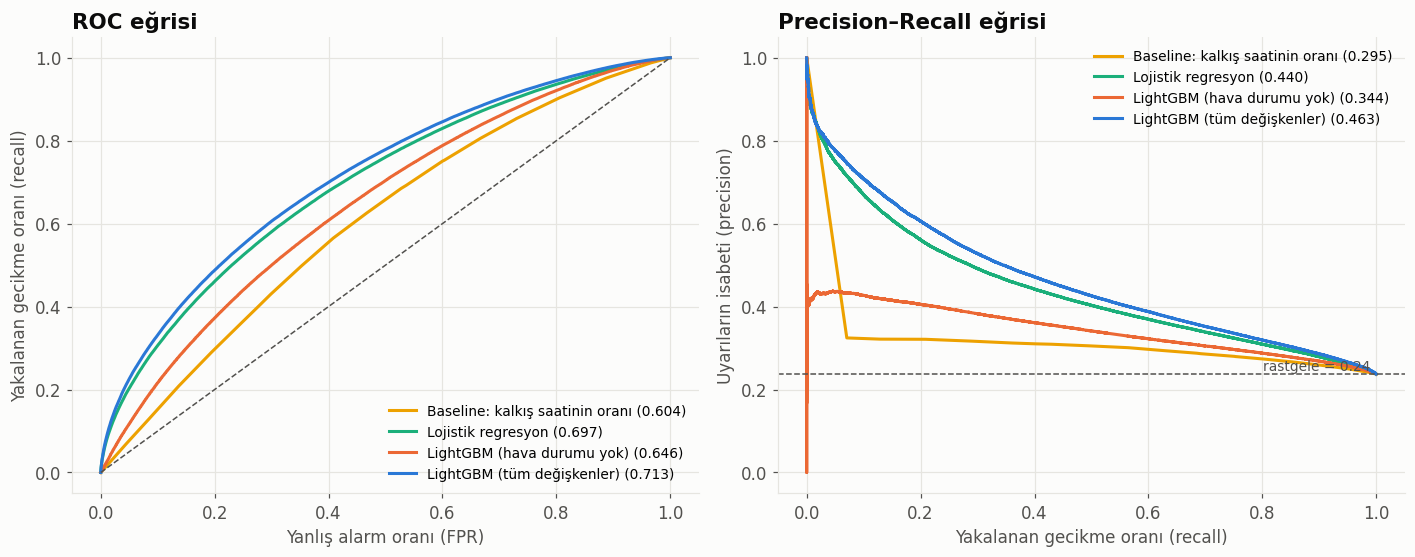

Kaydedildi: figures/11_roc_pr_egrileri.png


In [8]:
show = ['Baseline: kalkış saatinin oranı', 'Lojistik regresyon', 'LightGBM (hava durumu yok)', 'LightGBM (tüm değişkenler)']
colors = [YELLOW, AQUA, ORANGE, BLUE]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for name, col in zip(show, colors):
    fpr, tpr, _ = roc_curve(y_te, curves[name])
    axes[0].plot(fpr, tpr, color=col, lw=2, label=f"{name} ({results[name]['ROC-AUC (test)']:.3f})")
    pr, rc, _ = precision_recall_curve(y_te, curves[name])
    axes[1].plot(rc, pr, color=col, lw=2, label=f"{name} ({results[name]['PR-AUC (test)']:.3f})")
axes[0].plot([0, 1], [0, 1], color=INK2, lw=1, ls='--')
axes[0].set(xlabel='Yanlış alarm oranı (FPR)', ylabel='Yakalanan gecikme oranı (recall)', title='ROC eğrisi')
axes[1].axhline(y_te.mean(), color=INK2, lw=1, ls='--')
axes[1].text(0.99, y_te.mean() + 0.01, f'rastgele = {y_te.mean():.2f}', ha='right', color=INK2, fontsize=9)
axes[1].set(xlabel='Yakalanan gecikme oranı (recall)', ylabel='Uyarıların isabeti (precision)', title='Precision–Recall eğrisi')
for ax in axes:
    ax.legend(loc='lower right' if ax is axes[0] else 'upper right', fontsize=9, frameon=False)
save(fig, '11_roc_pr_egrileri')

## 7. Eşik seçimi ve iş metrikleri
Model bir **olasılık** veriyor. "Gecikecek" demek için bir eşik seçmemiz lazım. Eşiği **doğrulama setinde** F1'i en yüksek yapacak şekilde seçiyoruz,
sonra testte bir kez ölçüyoruz.

In [9]:
p_va = model.predict(va[FEATURES], num_iteration=model.best_iteration)
p_te = model.predict(te[FEATURES], num_iteration=model.best_iteration)
pr, rc, th = precision_recall_curve(y_va, p_va)
f1s = 2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-9)
THR = float(th[np.argmax(f1s)])
pred = (p_te >= THR).astype(int)
tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
print(f'Seçilen eşik (doğrulamada en yüksek F1): {THR:.3f}\n')
print(f'TEST — precision: {precision_score(y_te, pred):.3f}  recall: {recall_score(y_te, pred):.3f}  F1: {f1_score(y_te, pred):.3f}')
print(f'Karışıklık matrisi: doğru alarm {tp:,} | yanlış alarm {fp:,} | kaçırılan gecikme {fn:,} | doğru "zamanında" {tn:,}')

# İş açısından: en riskli %X uçuşa uyarı verirsek ne olur?
order = np.argsort(-p_te)
rows = []
for share in (0.05, 0.10, 0.20, 0.30):
    k = int(len(p_te) * share)
    sel = y_te[order[:k]]
    rows.append({'uyarı verilen uçuşlar': f'en riskli %{int(share * 100)}', 'uçuş': k,
                 'bunların gerçekten geciken payı': f'%{sel.mean() * 100:.1f}',
                 'kat (ortalamaya göre)': round(sel.mean() / y_te.mean(), 2),
                 'tüm gecikmelerin yakalanan payı': f'%{sel.sum() / y_te.sum() * 100:.1f}'})
lift = pd.DataFrame(rows)
print('\nİş tablosu (test):')
print(lift.to_string(index=False))

Seçilen eşik (doğrulamada en yüksek F1): 0.194

TEST — precision: 0.384  recall: 0.610  F1: 0.471
Karışıklık matrisi: doğru alarm 163,117 | yanlış alarm 261,569 | kaçırılan gecikme 104,165 | doğru "zamanında" 598,368

İş tablosu (test):
uyarı verilen uçuşlar   uçuş bunların gerçekten geciken payı  kat (ortalamaya göre) tüm gecikmelerin yakalanan payı
         en riskli %5  56360                           %66.3                   2.80                           %14.0
        en riskli %10 112721                           %57.2                   2.41                           %24.1
        en riskli %20 225443                           %47.2                   1.99                           %39.8
        en riskli %30 338165                           %41.6                   1.75                           %52.6


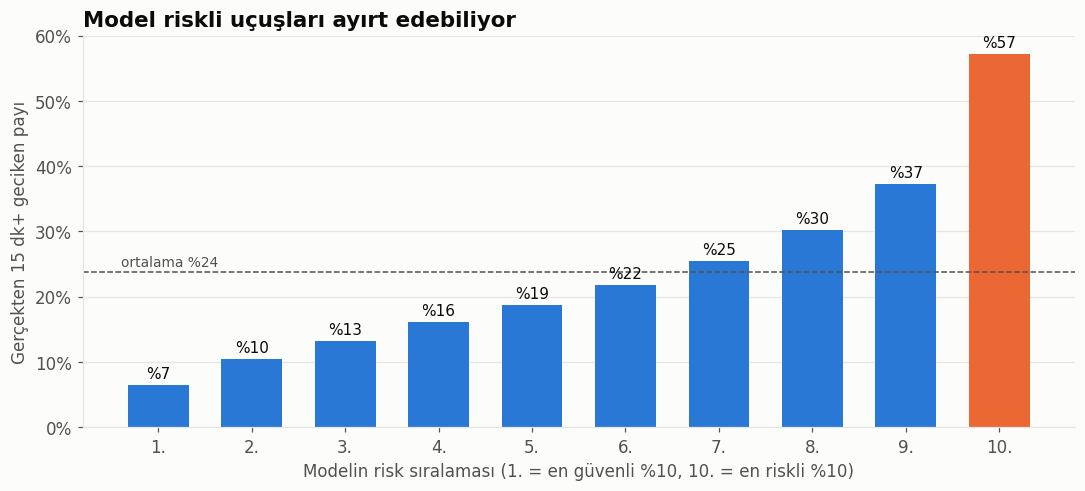

Kaydedildi: figures/12_risk_dilimleri.png


In [10]:
dec = pd.DataFrame({'p': p_te, 'y': y_te})
dec['dilim'] = pd.qcut(dec['p'].rank(method='first'), 10, labels=False) + 1
d = dec.groupby('dilim')['y'].mean()
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar(d.index, d.values, width=0.65, color=[ORANGE if i == 10 else BLUE for i in d.index], zorder=2)
for x, v in zip(d.index, d.values):
    ax.text(x, v + 0.01, f'%{v * 100:.0f}', ha='center', color=INK, fontsize=10)
ax.axhline(y_te.mean(), color=INK2, lw=1, ls='--')
ax.text(0.6, y_te.mean() + 0.01, f'ortalama %{y_te.mean() * 100:.0f}'.replace('.', ','), color=INK2, fontsize=9)
ax.set_xticks(range(1, 11), [f'{i}.' for i in range(1, 11)])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.grid(axis='x', visible=False)
ax.set_xlabel('Modelin risk sıralaması (1. = en güvenli %10, 10. = en riskli %10)')
ax.set_ylabel('Gerçekten 15 dk+ geciken payı')
ax.set_title('Model riskli uçuşları ayırt edebiliyor')
save(fig, '12_risk_dilimleri')

## 8. Hangi değişkenler önemli?
LightGBM'in kendi SHAP katkıları (`pred_contrib`) ile 50 bin test uçuşunda her değişkenin tahmine ortalama etkisi.

Kalkış saati (dakika)             9.7
Havayolu                          7.4
Kalkış havalimanı                 5.7
Varış saati                       5.5
Varış havalimanı                  5.4
Havayolunun günlük uçuşu          4.6
Kalkışta yağış                    4.1
Varışta yağış                     3.9
Varışta en düşük sıcaklık         3.7
Kalkışta en düşük sıcaklık        3.6
Haftanın günü                     3.4
Kalkış saati                      3.1
Tatile uzaklık                    3.1
Planlanan uçuş süresi             3.1
Varış hav. saatlik planlı iniş    2.8
Kalkışta sis                      2.8
Kalkışta en yüksek sıcaklık       2.7
Varışta sis                       2.6
Varışta en yüksek sıcaklık        2.6
Kalkışta en sert rüzgar           2.6


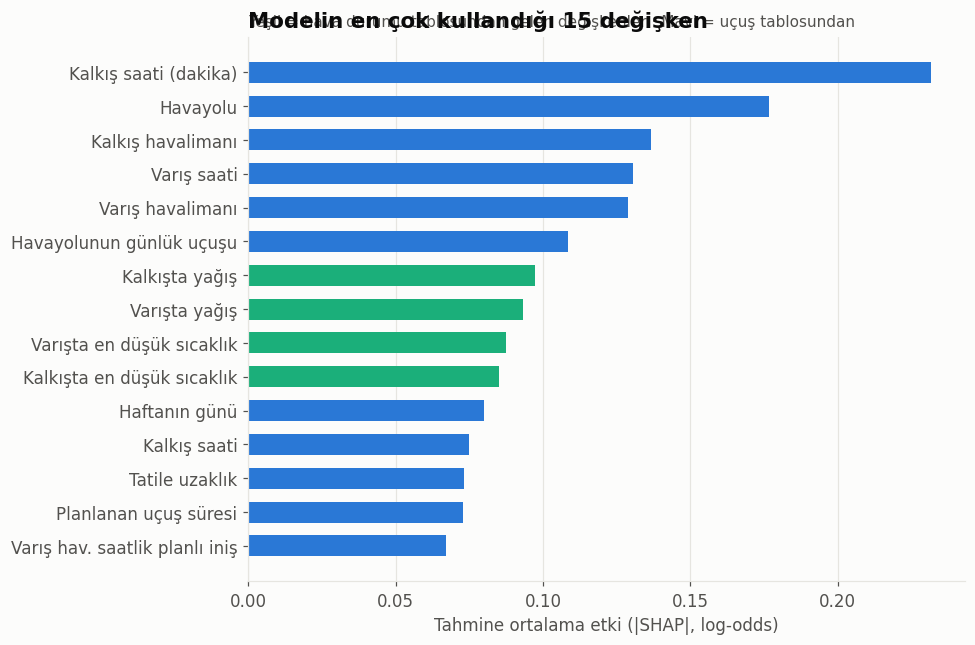

Kaydedildi: figures/13_degisken_onemi.png

Hava durumu değişkenlerinin toplam önemdeki payı: %40


In [11]:
samp = te.sample(min(50_000, len(te)), random_state=RNG)
contrib = model.predict(samp[FEATURES], num_iteration=model.best_iteration, pred_contrib=True)
imp = pd.Series(np.abs(contrib[:, :-1]).mean(axis=0), index=FEATURES).sort_values(ascending=False)
NAMES = {'dep_minute': 'Kalkış saati (dakika)', 'dep_hour': 'Kalkış saati', 'arr_hour': 'Varış saati', 'airline': 'Havayolu',
         'origin': 'Kalkış havalimanı', 'dest': 'Varış havalimanı', 'day_of_week': 'Haftanın günü',
         'origin_sched_dep_day': 'Kalkış hav. günlük planlı uçuş', 'origin_sched_dep_hour': 'Kalkış hav. saatlik planlı uçuş',
         'dest_sched_arr_hour': 'Varış hav. saatlik planlı iniş', 'airline_sched_day': 'Havayolunun günlük uçuşu',
         'days_to_holiday': 'Tatile uzaklık', 'is_holiday': 'Tatil günü', 'crs_elapsed_min': 'Planlanan uçuş süresi',
         'distance_mi': 'Mesafe'}
TR_WX = {'tmax_c': 'en yüksek sıcaklık', 'tmin_c': 'en düşük sıcaklık', 'prcp_mm': 'yağış', 'snow_mm': 'kar', 'snwd_mm': 'yerdeki kar',
         'awnd_ms': 'ortalama rüzgar', 'wsf2_ms': 'en sert rüzgar', 'fog': 'sis', 'thunder': 'fırtına', 'hail': 'dolu',
         'freezing': 'don', 'heavy_rain': 'yoğun yağış', 'snow_day': 'kar günü'}
for c in WX:
    NAMES[f'o_{c}'] = f'Kalkışta {TR_WX[c]}'
    NAMES[f'd_{c}'] = f'Varışta {TR_WX[c]}'
top = imp.head(15)[::-1]
print((imp / imp.sum() * 100).round(1).rename(index=NAMES).head(20).to_string())
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh([NAMES.get(i, i) for i in top.index], top.values, height=0.62,
        color=[AQUA if (i.startswith('o_') or i.startswith('d_')) else BLUE for i in top.index], zorder=2)
ax.grid(axis='y', visible=False)
ax.set_xlabel('Tahmine ortalama etki (|SHAP|, log-odds)')
ax.set_title('Modelin en çok kullandığı 15 değişken')
ax.text(0, 1.02, 'Yeşil = hava durumu tablosundan gelen değişkenler · Mavi = uçuş tablosundan', transform=ax.transAxes, color=INK2, fontsize=10)
save(fig, '13_degisken_onemi')
wx_share = imp[[i for i in imp.index if i.startswith(('o_', 'd_'))]].sum() / imp.sum()
print(f'\nHava durumu değişkenlerinin toplam önemdeki payı: %{wx_share * 100:.0f}')

## 9. Hata analizi: model nerede iyi, nerede zorlanıyor?

In [12]:
te_eval = te[['airline', 'origin', 'dep_hour', 'o_snow_day', 'o_thunder']].copy()
te_eval['y'], te_eval['p'] = y_te, p_te
snow = te_eval['o_snow_day'].astype('float64').fillna(0).to_numpy() == 1
thunder = te_eval['o_thunder'].astype('float64').fillna(0).to_numpy() == 1
te_eval['hava'] = np.select([snow, thunder], ['kar', 'fırtına'], 'normal')
print('Hava koşuluna göre test ROC-AUC:')
for k, gdf in te_eval.groupby('hava'):
    if gdf['y'].nunique() == 2:
        print(f'  {k:8s} {len(gdf):>9,} uçuş   gerçek oran %{gdf["y"].mean() * 100:5.1f}   tahmin ort. %{gdf["p"].mean() * 100:5.1f}   AUC {roc_auc_score(gdf["y"], gdf["p"]):.3f}')
print('\nHavayoluna göre test: gerçek ve tahmin edilen ortalama gecikme oranı (kalibrasyon)')
cal = te_eval.groupby('airline', observed=True).agg(ucus=('y', 'size'), gercek=('y', 'mean'), tahmin=('p', 'mean'))
print((cal.assign(gercek=lambda x: (x['gercek'].astype(float) * 100).round(1), tahmin=lambda x: (x['tahmin'].astype(float) * 100).round(1))
          .sort_values('ucus', ascending=False)).to_string())

Hava koşuluna göre test ROC-AUC:
  fırtına     29,577 uçuş   gerçek oran % 35.1   tahmin ort. % 31.1   AUC 0.766
  kar         50,514 uçuş   gerçek oran % 54.3   tahmin ort. % 45.1   AUC 0.713
  normal   1,047,128 uçuş   gerçek oran % 21.9   tahmin ort. % 17.9   AUC 0.694

Havayoluna göre test: gerçek ve tahmin edilen ortalama gecikme oranı (kalibrasyon)
           ucus  gercek  tahmin
airline                        
WN       229030    22.4    17.8
DL       165490    21.6    18.3
AA       156315    25.0    21.1
OO       132425    22.6    20.2
UA       131068    21.7    17.7
YX        56939    27.2    17.4
MQ        48351    20.7    20.0
AS        40117    23.6    21.2
B6        39124    30.6    24.0
OH        38728    30.4    25.8
F9        32922    27.7    25.0
NK        22857    27.5    14.3
G4        20912    27.3    22.5
HA        12941    23.3    14.0


## 10. Modeli kaydet (Streamlit demosu için)

In [13]:
model.save_model(str(MODELS / 'lgbm_delay.txt'), num_iteration=model.best_iteration)
meta = {
    'features': FEATURES, 'categorical': CAT, 'threshold': THR,
    'categories': {c: list(map(str, tr[c].cat.categories)) for c in CAT},
    'train_months': TRAIN_M, 'valid_months': VALID_M, 'test_months': TEST_M,
    'test_metrics': {k: float(v) for k, v in results['LightGBM (tüm değişkenler)'].items()},
    'base_rate_test': float(y_te.mean()),
}
(MODELS / 'model_meta.json').write_text(json.dumps(meta, ensure_ascii=False, indent=1))
res.to_csv(MODELS / 'model_sonuclari.csv')
print('Kaydedildi:', sorted(p.name for p in MODELS.iterdir()))

Kaydedildi: ['lgbm_delay.txt', 'model_meta.json', 'model_sonuclari.csv']


**Yorum — model sonuçları**

**1. Model, basit kurallardan açıkça daha iyi.**

| Model | ROC-AUC (test) | PR-AUC (test) |
|---|---|---|
| Rastgele | 0,500 | 0,237 |
| Baseline: havalimanı × saat oranı | 0,616 | 0,309 |
| Lojistik regresyon | 0,697 | 0,440 |
| LightGBM, hava durumu yok | 0,646 | 0,344 |
| **LightGBM, tüm değişkenler** | **0,713** | **0,463** |

PR-AUC rastgele tahminin **yaklaşık 2 katı**. Lojistik regresyon LightGBM'e yakın → ilişkilerin önemli kısmı basit ve yorumlanabilir; LightGBM etkileşimleri (ör. havalimanı × hava durumu) yakalayarak üstüne ekliyor.

**2. Hava durumu tablosu en büyük kazancı getirdi (çok tablolu verinin değeri).** Hava durumu olmadan ROC-AUC 0,646 → hava durumuyla 0,713 (**+0,067**); PR-AUC 0,344 → 0,463 (**+0,119, %35 iyileşme**). Değişken öneminin **%40'ı** hava durumu sütunlarından geliyor.

**3. İş açısından:** Model en riskli %10'luk uçuşa uyarı verirse bu uçuşların **%57'si gerçekten gecikiyor** (ortalama %24 → **2,4 kat isabet**) ve tüm gecikmelerin **%24'ü** önceden işaretlenmiş oluyor. En riskli %5'te isabet **%66**. Risk dilimlerine göre gerçek gecikme oranı %7'den (en güvenli dilim) %57'ye (en riskli dilim) çıkıyor → model riskli ve güvenli uçuşları net ayırıyor.
- **Eşik 0,194** (doğrulamada en yüksek F1): testte precision %38, recall %61, F1 0,47. Yani gecikmelerin %61'i yakalanıyor; her 100 uyarının 38'i gerçek gecikme. Eşik iş ihtiyacına göre kaydırılabilir: yolcuya SMS için yüksek isabet (dar liste), operasyon planlaması için yüksek yakalama (geniş liste).

**4. En önemli değişkenler** EDA ile tutarlı: kalkış saati (domino etkisi), havayolu, kalkış/varış havalimanı, havayolunun o günkü uçuş yoğunluğu, ardından yağış ve sıcaklık (don/kar).

**5. Hata analizi ve sınırlamalar (dürüst değerlendirme)**
- Model **kötü havada daha iyi** ayırt ediyor (fırtınalı günlerde AUC 0,77, karlı günlerde 0,71, normal günlerde 0,69). Normal havadaki gecikmeler daha çok önceden bilinmeyen operasyonel sebeplerden (önceki seferin rötarı, ekip, bakım) kaynaklanıyor.
- **Olasılıklar testte düşük kalıyor:** Model ortalama %18 tahmin ediyor, gerçek oran %24. Sebep **dağılım kayması**: test dönemi (Kasım–Aralık) yılın en yoğun tatil dönemi ve gecikme oranı eğitimden yüksek. Sıralama (AUC) sağlam, ama demoda gösterilecek olasılıklar için **yeniden kalibrasyon** gerekli.
- Bazı havayollarında fark büyük (ör. Spirit: gerçek %27,5, tahmin %14,3; Republic: %27,2 / %17,4). Olası açıklama: yıl içinde havayolunun kendisinde yapısal değişiklik (Spirit 2025'te mali yeniden yapılanma sürecindeydi) — model eğitim döneminde olmayan bu değişimi bilemez. Gerçek kullanımda model **düzenli olarak yeniden eğitilmeli**.
- Veride uçak kuyruk numarası yok → "aynı uçağın önceki seferi gecikti mi?" bilgisi kullanılamadı (gecikme dakikalarının %39'unun sebebi bu). Gerçekleşen hava durumu kullanıldı; gerçek hayatta hava **tahmini** kullanılmalı.

**Sonraki adımlar:** olasılık kalibrasyonu, kuyruk numaralı veriyle "önceki sefer" değişkeni, hava tahmini verisi, aylık yeniden eğitim.

## Bitti
Sonraki adım: Streamlit demosu.